# 17 · 真实搜索：词法、语义、融合与重排

这是同一搜推广告系统的搜索迭代。复用 `reclab.experiments`、排序指标、粗索引、FastAPI 与工作台；不从推荐日志伪造查询。

**先预测**：生物医学领域，通用 MiniLM 是否必然优于 BM25？TinyBERT 重排能否找回候选集之外的论文？粗索引探测全部簇是否等价于精确检索？

**数据边界**：BEIR SciFact 全部 5,183 篇文档、300 个测试查询。按查询 ID 字典序选 200/809 个训练查询，仅训练小型线性排序器。所有模型参数、RRF 常数与候选预算事先固定，不按测试成绩调参。神经模型冻结，无神经微调；不是完整 BEIR 论文复现。未判断文档按不相关计分，不能据此证实负相关。

In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if not (root / "reclab").exists(): root = root.parent
os.chdir(root)
sys.path.insert(0, str(root))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from reclab.search import latest, verify_sources, BM25, rrf
from reclab.retrieval import topk
receipt, result = latest()
verify_sources()
print(receipt['run_id'], result['scope'])
print('所有20项公开输入SHA已核验；数据/权重不进入Git。')

20261030T124927-d1467622 SciFact BEIR: all 5,183 documents, all 300 test queries; 200 lexicographically selected train queries; frozen MiniLM/TinyBERT, no neural fine-tuning. Unjudged documents treated as nonrelevant, not verified negatives.
所有20项公开输入SHA已核验；数据/权重不进入Git。


## 查看实际实验

MiniLM：6层、384维、归一化 mean pooling，最多256 wordpieces。TinyBERT：2层交叉编码器，最多256个联合tokens。BM25使用全语料词频；RRF对两个前100结果按 `1/(60+rank)` 求和。重排只看融合前20，不能提高前20的候选召回上限。

线性模型在训练查询前20候选上，以 BM25、余弦、RRF、查询词覆盖和篇幅为特征拟合 LogisticRegression。未判断候选作为弱负标签，可能存在假负例。其输出用于排序，不声称为校准相关概率。

,recall@10,ndcg@10,mrr@10,hit_rate@10,recall@100,latency_p50_ms,latency_p95_ms,known_positive_fraction@10
method,,,,,,,,
bm25,0.7909,0.6617,0.6276,0.8100,0.8859,2.3056,3.0286,0.0873
dense,0.7883,0.6484,0.6068,0.8000,0.9250,13.2233,14.7887,0.0890
hybrid_rrf,0.8089,0.6855,0.6510,0.8267,0.9550,15.6706,17.3551,0.0907
linear_rerank,0.8107,0.7034,0.6747,0.8267,0.8752,17.1305,18.8177,0.0910
tinybert_rerank,0.7868,0.6670,0.6357,0.8000,0.8752,50.9085,55.7259,0.0890
dense_coarse2,0.6242,0.5153,0.4848,0.6367,0.6942,12.9576,14.7254,0.0723
dense_coarse12,0.7883,0.6484,0.6068,0.8000,0.9250,14.4022,16.2226,0.0890


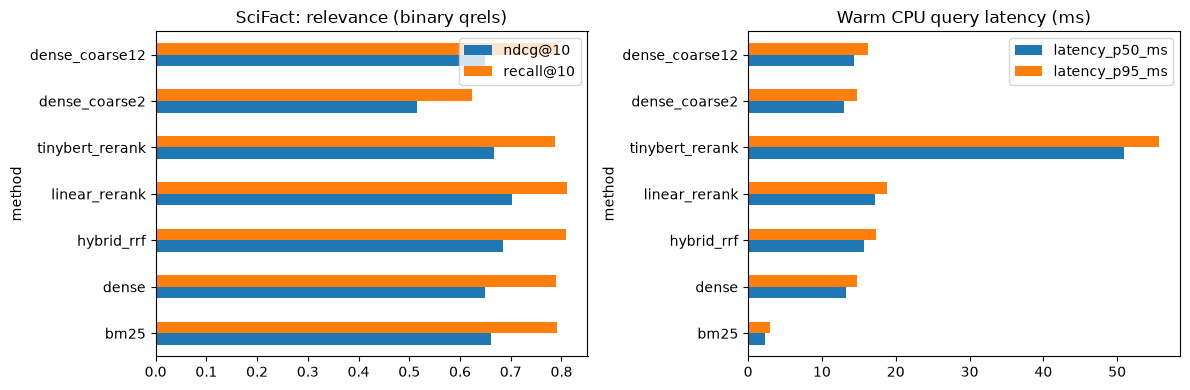

候选Recall@20: 0.8752222222222222
近似索引: {'dense_coarse2': {'exact_top10_agreement': 0.7679999999999999, 'mean_candidates': 879.9366666666666}, 'dense_coarse12': {'exact_top10_agreement': 1.0, 'mean_candidates': 5183.0}}


In [2]:
table = pd.DataFrame(result['rows']).set_index('method')
display(table.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
table[['ndcg@10','recall@10']].plot.barh(ax=axes[0], title='SciFact: relevance (binary qrels)')
table[['latency_p50_ms','latency_p95_ms']].plot.barh(ax=axes[1], title='Warm CPU query latency (ms)')
plt.tight_layout(); plt.show()
print('候选Recall@20:', result['rerank_candidate_recall@20'])
print('近似索引:', result['approximation'])
assert result['approximation']['dense_coarse12']['exact_top10_agreement'] == 1.0

## 只改一个变量：融合深度

**先预测**：只取一个通道的首名与取前两名，融合结果如何变化？下面是构造排名的机制检查，绝不是 SciFact 成绩。把 `depth=1` 改为2再运行，并解释变化。要得到真实数据新成绩，显式运行 `run(Config(candidate_depth=..., rerank_depth=...))`；每次新建实验，不覆盖既有训练。

延迟是实测逐查询CPU墙钟时间，含查询tokenization、编码、排序与对应重排；不含模型加载、离线语料编码、磁盘、HTTP。各方法混合顺序测量，不能当生产QPS。

In [3]:
toy_rankings = [[2, 1, 3], [3, 1, 2]]
for depth in [1, 2]:
    print('depth', depth, topk(rrf(toy_rankings, 3, depth=depth), 3))
# 查看正式算法源码；本格不自动训练。
import inspect
from reclab import search
print(inspect.getsource(search.rrf))

depth 1 [2, 3]
depth 2 [1, 2, 3]
def rrf(rankings, n_documents, depth=100, constant=60):
    scores = np.zeros(n_documents + 1)
    scores[0] = -np.inf
    for ranking in rankings:
        for rank, doc in enumerate(ranking[:depth], 1):
            scores[doc] += 1 / (constant + rank)
    # Documents outside the candidate union must never fill a truncated candidate list.
    scores[scores == 0] = -np.inf
    return scores



## 失败案例与候选上限

按 TinyBERT 相对 BM25 的 NDCG 降幅排序，查看固定8个查询，不能只挑获胜案例。不同查询可能涉及词汇缺失、领域术语、截断、标注稀疏或预训练领域差异；这些是待验证解释，不是因果结论。

**解释对照**：找一个 BM25 命中而重排退化的查询；先检查前20是否包含目标，再区分召回失败与排序失败。完整逐查询列表保存在本机实验目录 `per_query.json`。

In [4]:
for failure in result['failures'][:3]:
    print('Query ID', failure['qid'])
    print('Relevant documents', failure['relevant_document_ids'])
    display(pd.DataFrame(failure['metrics']).T[['ndcg@10','mrr@10','recall@10']].round(3))
    # 本机 result['failures'] 可查看原查询/标题；Git只保留ID与精简指标。
# 数值上确认：在同一前20候选集内重排，Recall@100必须相同。
assert np.isclose(table.loc['linear_rerank','recall@100'], result['rerank_candidate_recall@20'])
assert np.isclose(table.loc['tinybert_rerank','recall@100'], result['rerank_candidate_recall@20'])

Query ID 1363
Relevant documents ['8290953']


,ndcg@10,mrr@10,recall@10
bm25,1.000,1.000,1.0
dense,0.000,0.000,0.0
hybrid_rrf,0.333,0.143,1.0
linear_rerank,1.000,1.000,1.0
tinybert_rerank,0.000,0.000,0.0
dense_coarse2,0.000,0.000,0.0
dense_coarse12,0.000,0.000,0.0


Query ID 659
Relevant documents ['1215116']


,ndcg@10,mrr@10,recall@10
bm25,1.0,1.0,1.0
dense,1.0,1.0,1.0
hybrid_rrf,1.0,1.0,1.0
linear_rerank,1.0,1.0,1.0
tinybert_rerank,0.0,0.0,0.0
dense_coarse2,0.0,0.0,0.0
dense_coarse12,1.0,1.0,1.0


Query ID 660
Relevant documents ['1215116']


,ndcg@10,mrr@10,recall@10
bm25,1.000,1.000,1.0
dense,0.000,0.000,0.0
hybrid_rrf,0.315,0.125,1.0
linear_rerank,0.000,0.000,0.0
tinybert_rerank,0.000,0.000,0.0
dense_coarse2,0.000,0.000,0.0
dense_coarse12,0.000,0.000,0.0


## 如何复现与继续

```bash
.venv/bin/python -m reclab.search --download
.venv/bin/python scripts/execute_notebooks.py --only 17_Search_Experiments
```

新实验进入同一07工作台和 `/api/experiments/search/{run_id}`。工作台可输入英文声明，实际检索这套本机语料。

[数据原作者](https://github.com/allenai/scifact) · [BEIR数据CC BY-SA 4.0](https://huggingface.co/datasets/BeIR/scifact) · [MiniLM Apache-2.0](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) · [TinyBERT Apache-2.0](https://huggingface.co/cross-encoder/ms-marco-TinyBERT-L-2-v2)。固定版本与SHA见 `docs/search_sources.json`。英文科学证据检索不代表通用网络搜索；预训练语料可能重叠，不声称严格无泄漏基准或医学结论。